In [2]:
import pandas as pd 
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

In [3]:
df=pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv')

In [4]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [5]:
# Use only the provided columns
df_data = df[['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']]
df= df_data
print(df.head())
print()
print(df.info())

   engine_displacement  horsepower  vehicle_weight  model_year  \
0                 2180       243.0            3870        2006   
1                 2390       272.0            4210        2008   
2                 2320       267.0            4240        1996   
3                 2130       258.0            4490        1989   
4                 2580       304.0            4510        1994   

   fuel_efficiency_mpg  
0                 31.9  
1                 31.3  
2                 27.5  
3                 28.5  
4                 31.0  

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   engine_displacement  10000 non-null  int64  
 1   horsepower           9123 non-null   float64
 2   vehicle_weight       10000 non-null  int64  
 3   model_year           10000 non-null  int64  
 4   fuel_efficiency_mpg  10000 non-null  float64
dtypes

# EDA

In [6]:
# Checking content of columns
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()

engine_displacement
[2180 2390 2320 2130 2580]
127

horsepower
[243. 272. 267. 258. 304.]
153

vehicle_weight
[3870 4210 4240 4490 4510]
176

model_year
[2006 2008 1996 1989 1994]
50

fuel_efficiency_mpg
[31.9 31.3 27.5 28.5 31. ]
188



<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

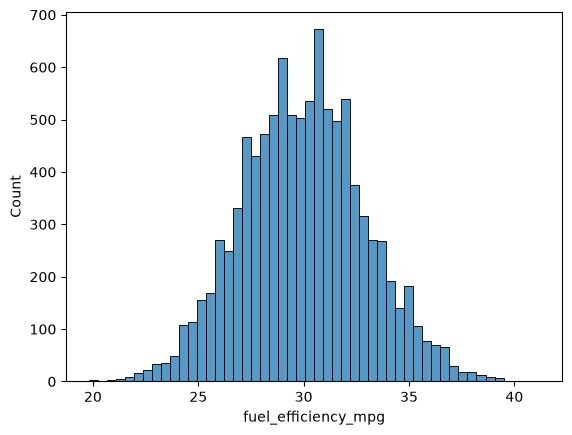

In [7]:
sns.histplot(df['fuel_efficiency_mpg'],bins=50)

### No,it does not have a long tail

# 1. Missing values

In [8]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

### A1: horsepower

# 2. Median for horsepower

In [9]:
df['horsepower'].median().astype('int')

np.int64(254)

# Prepare and split the dataset

In [10]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [11]:
df_train

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
6252,1900,239.0,3790,2015,32.5
4684,2000,224.0,4380,1992,29.1
1731,2330,286.0,4090,2022,34.1
4742,2300,NaN,4150,1997,30.6
4521,2340,269.0,4400,2001,30.7
...,...,...,...,...,...
7895,2280,242.0,4590,2018,29.8
9590,2300,NaN,4240,1984,25.1
7288,2240,255.0,4190,1989,27.7
278,2430,254.0,4280,2020,31.6


In [12]:
df_train.reset_index(drop = True, inplace = True)
df_val.reset_index(drop = True, inplace = True)
df_test.reset_index(drop = True, inplace = True)

In [13]:
df_train

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,1900,239.0,3790,2015,32.5
1,2000,224.0,4380,1992,29.1
2,2330,286.0,4090,2022,34.1
3,2300,NaN,4150,1997,30.6
4,2340,269.0,4400,2001,30.7
...,...,...,...,...,...
5995,2280,242.0,4590,2018,29.8
5996,2300,NaN,4240,1984,25.1
5997,2240,255.0,4190,1989,27.7
5998,2430,254.0,4280,2020,31.6


In [14]:
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

In [15]:
y_train

array([32.5, 29.1, 34.1, ..., 27.7, 31.6, 28. ], shape=(6000,))

In [16]:
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

# 3. Filling NAs

In [18]:
features = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']

# Function to train Linear Regression model
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

# Function to computer RMSE
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

# Function to fill missing values with a specified value
def prepare_X(df, fill):
    df_num = df[features]
    df_num = df_num.fillna(fill)
    X = df_num.values
    return X

### With mean:

In [22]:
mean = df_test['horsepower'].mean().astype('int')
print(mean)

254


In [23]:
X_train = prepare_X(df_train, mean)
w0, w = train_linear_regression(X_train, y_train)
y_pred = w0 + X_train.dot(w)
print('model trained after filling missing values with mean')

model trained after filling missing values with mean


In [25]:
# Using the validation dataset to evaluate the model

X_val = prepare_X(df_val, mean)
y_pred = w0 + X_val.dot(w)
print('RMSE (filling missing values with mean): ', rmse(y_val, y_pred).round(3))

RMSE (filling missing values with mean):  2.202


### With 0:

In [19]:
X_train = prepare_X(df_train, 0)
w0, w = train_linear_regression(X_train, y_train)
y_pred = w0 + X_train.dot(w)
rms_error = rmse(y_train, y_pred)
print('model trained after filling missing values with 0')

model trained after filling missing values with 0


In [20]:
# Using the validation dataset to evaluate the model

X_val = prepare_X(df_val, 0)
y_pred = w0 + X_val.dot(w)
print('RMSE (filling missing values with 0): ', rmse(y_val, y_pred).round(3))

RMSE (filling missing values with 0):  2.205


# 4. Best regularization

In [26]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

In [27]:
r_list = [0, 0.01, 0.1, 1, 5, 10, 100]
for r in r_list:
    X_train = prepare_X(df_train, 0)
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)

    X_val = prepare_X(df_val, 0)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)
    
    print(r, "\t: ", score.round(4))

0 	:  2.2053
0.01 	:  2.2058
0.1 	:  2.2241
1 	:  2.3492
5 	:  2.4094
10 	:  2.4195
100 	:  2.4292


### 0 gives the best RMSE

# 5. RMSE standard deviation

In [29]:
seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

# List of RMSE scores
scores = []

In [42]:
for seed in seeds:
    # Read the dataset into a datframe
    df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv')
    n = len(df)

    idx = np.arange(n)
    np.random.seed(seed)
    np.random.shuffle(idx)
    
    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train+n_val]]
    df_test = df.iloc[idx[n_train+n_val:]]


    # Select the numerical coulumns
    df = df[['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']]

    # split the dataset in train/val/test sets, with 60%/20%/20% distribution
    n_val = int(n * 0.2) 
    n_test = int(n * 0.2) 
    n_train = n - n_val - n_test 

    y_train = df_train.fuel_efficiency_mpg.values
    y_val = df_val.fuel_efficiency_mpg.values
    y_test = df_test.fuel_efficiency_mpg.values

    # Delete the target variable from the dataframe
    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']
    del df_test['fuel_efficiency_mpg']

    # Training alinear regression model (with filling null values with zero)
    X_train = prepare_X(df_train, 0)
    w0, w = train_linear_regression(X_train, y_train)
    y_pred = w0 + X_train.dot(w)

    # Evaluating the model on validation set
    X_val = prepare_X(df_val, 0)
    y_pred = w0 + X_val.dot(w)
    rms_error = rmse(y_val, y_pred)

    scores.append(rms_error.round(4))

In [43]:
scores

[np.float64(2.24),
 np.float64(2.2),
 np.float64(2.16),
 np.float64(2.2),
 np.float64(2.2),
 np.float64(2.25),
 np.float64(2.27),
 np.float64(2.19),
 np.float64(2.22),
 np.float64(2.21),
 np.float64(2.239),
 np.float64(2.202),
 np.float64(2.163),
 np.float64(2.204),
 np.float64(2.202),
 np.float64(2.246),
 np.float64(2.27),
 np.float64(2.191),
 np.float64(2.217),
 np.float64(2.207),
 np.float64(2.2392),
 np.float64(2.2021),
 np.float64(2.1634),
 np.float64(2.2044),
 np.float64(2.2019),
 np.float64(2.2458),
 np.float64(2.2697),
 np.float64(2.1908),
 np.float64(2.2166),
 np.float64(2.207)]

In [44]:
std_dev = round(np.std(scores), 3)
print(std_dev)

0.029


# 6. Evaluation on test

In [45]:
# Read the dataset into a datframe
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv')
n = len(df)

idx = np.arange(n)
np.random.seed(9)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train+n_val]]
df_test = df.iloc[idx[n_train+n_val:]]


# Select the numerical coulumns
df = df[['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']]

# split the dataset in train/val/test sets, with 60%/20%/20% distribution
n_val = int(n * 0.2) 
n_test = int(n * 0.2) 
n_train = n - n_val - n_test 

y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

# Delete the target variable from the dataframe
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']


df_full_train = pd.concat([df_train, df_val])
df_full_train = df_full_train.reset_index(drop=True)
X_full_train = prepare_X(df_full_train, 0)

y_full_train = np.concatenate([y_train, y_val])
w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)

X_test = prepare_X(df_test, 0)
y_pred = w0 + X_test.dot(w)
score = rmse(y_test, y_pred)

In [46]:
print(score.round(3))

2.236
